# 04 · Hallucination Classifier + SHAP
**Grounded Conversational Chart Accessibility** — Section 4 of 6

**The question:** can we predict *which* answers are likely to be hallucinated **before checking them against the data**, and explain *why*?

That matters for accessibility: a system could warn a user about a risky answer even for a chart it can't verify (for example, an image with no data table).

**Label** (what we predict): `hallucinated` from Section 3. It was audited by hand at precision 0.98 / recall 1.00.

**Features** (what the classifier may look at): only things known *at the moment the LLM answers*, without the true answer:

| group | features |
|---|---|
| who answered | `model`, `style` (short / sentence) |
| what was asked | `qtype`, `question_words` |
| the chart | `chart_type`, `table_rows`, `table_cols` |
| the answer itself | `answer_words`, `answer_numbers`, `is_refusal`, `is_hedged` ("approximately"…), `names_a_category`, `number_only_for_name_question` |

**Why not numeric deviation, fuzzy score and cosine similarity?** Those compare the answer with the *true* answer, which is exactly how the verifier decides the label. A classifier given them would just relearn the verifier's thresholds and score near 100%, which proves nothing. (Section 4.7 runs that model anyway, as a sanity check, so you can show reviewers the trap.)

**Models:** Logistic Regression (simple, readable weights) and Random Forest (captures interactions), plus a **baseline** that only knows the model and answer style, to check the classifier learns more than "Llama is worse than Gemini".

## 4.1 Setup

In [1]:
# First time only:  py -3.12 -m pip install scikit-learn shap
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import shap
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

from src import config
from src.features import build_features, CATEGORICAL, NUMERIC

config.make_dirs()
config.set_seeds()

# Chart style (one blue ramp for magnitude, quiet axes; used by every figure here)
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#9ec5f4", "#3987e5", "#104281"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.edgecolor": "#d8d7d2", "font.size": 10})
print("Ready.")

c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ready.


## 4.2 Load the Section 3 results and build the features

`build_features` (in `src/features.py`) turns each of the 800 LLM answers into one row of numbers and categories, using only information available before checking.

In [2]:
v = pd.read_csv(config.OUTPUT_DIR / "verified.csv")
X = build_features(v)
y = v["hallucinated"].astype(int).values
groups = v["qid"].values

print(f"{len(X)} answers | hallucinated: {y.sum()} ({100 * y.mean():.1f}%)")
X.head()

800 answers | hallucinated: 188 (23.5%)


,model,style,qtype,chart_type,answer_words,question_words,answer_numbers,is_refusal,is_hedged,names_a_category,number_only_for_name_question,table_rows,table_cols
0,llama3.2-3b,short,lookup,line,1,13,1,0,0,0,0,6,1
1,llama3.2-3b,sentence,lookup,line,16,13,2,0,1,1,0,6,1
2,gemini-flash,short,lookup,line,1,13,1,0,0,0,0,6,1
3,gemini-flash,sentence,lookup,line,15,13,2,0,0,1,0,6,1
4,llama3.2-3b,short,compare,pie,1,8,1,0,0,0,1,3,1


## 4.3 Train/test split, without leakage

Each question was answered **4 times** (2 models × 2 styles). If one of those copies lands in training and another in testing, the classifier can recognise the *question* instead of learning what makes answers risky. That is leakage.

So we split by **question**: all 4 answers to a question go to the same side (`GroupShuffleSplit`, 70% train / 30% test, fixed seed). The check below must print **0 shared questions**.

In [3]:
split = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=config.SEED)
train_idx, test_idx = next(split.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

shared = set(groups[train_idx]) & set(groups[test_idx])
print(f"train: {len(train_idx)} answers | test: {len(test_idx)} answers | shared questions: {len(shared)}")
print(f"hallucination rate  train: {100 * y_train.mean():.1f}%   test: {100 * y_test.mean():.1f}%")

train: 560 answers | test: 240 answers | shared questions: 0
hallucination rate  train: 24.5%   test: 21.2%


## 4.4 Train the models

All three use `class_weight="balanced"`: only about 1 in 4 answers is hallucinated, and without this a model can look accurate by always guessing "correct".

- **Baseline**: Logistic Regression that only sees `model` and `style`.
- **Logistic Regression**: all features; numbers are standardised (needed for LR).
- **Random Forest**: all features; 300 trees, at least 3 answers per leaf (limits overfitting). Trees don't need standardising, so its features keep their real units, which makes the SHAP plots easier to read.

In [4]:
def one_hot():
    # two-option features (model, style) become ONE column, so SHAP shows each once
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="if_binary")

models = {
    "Baseline (model + style)": Pipeline([
        ("prep", ColumnTransformer([("cat", one_hot(), ["model", "style"])])),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))]),
    "Logistic Regression": Pipeline([
        ("prep", ColumnTransformer([("cat", one_hot(), CATEGORICAL), ("num", StandardScaler(), NUMERIC)])),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))]),
    "Random Forest": Pipeline([
        ("prep", ColumnTransformer([("cat", one_hot(), CATEGORICAL), ("num", "passthrough", NUMERIC)])),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                       random_state=config.SEED, n_jobs=-1))]),
}

rows, PRED, PROB = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    PRED[name] = model.predict(X_test)
    PROB[name] = model.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, PRED[name]),
                 "precision": precision_score(y_test, PRED[name]),
                 "recall": recall_score(y_test, PRED[name]),
                 "F1": f1_score(y_test, PRED[name]),
                 "ROC_AUC": roc_auc_score(y_test, PROB[name])})
metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics.to_csv(config.TABLE_OUT / "classifier_metrics.csv")
metrics

c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,precision,recall,F1,ROC_AUC
model,,,,,
Baseline (model + style),0.712,0.425,1.000,0.596,0.877
Logistic Regression,0.804,0.522,0.922,0.667,0.944
Random Forest,0.871,0.656,0.824,0.730,0.943


**Reading the metrics** (hallucinated = the positive class):
- **precision**: of the answers flagged as risky, how many really were hallucinated,
- **recall**: of the real hallucinations, how many were flagged,
- **F1**: the balance of the two,
- **ROC-AUC**: how well the model *ranks* risky answers above safe ones (0.5 = guessing, 1.0 = perfect).

For a warning system, **recall matters most**: missing a hallucination is worse than an unnecessary warning.

## 4.5 Is that result stable? (5-fold cross-validation)

One test split of 240 answers can be lucky or unlucky. Here we repeat the whole train/test procedure 5 times with different question groups held out (`GroupKFold`, still no leakage) and report the mean ± standard deviation.

In [5]:
cv = GroupKFold(n_splits=5)
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, groups=groups, cv=cv,
                       scoring=["precision", "recall", "f1", "roc_auc"])
    cv_rows.append({"model": name, **{
        m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}"
        for m in ["precision", "recall", "f1", "roc_auc"]}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.to_csv(config.TABLE_OUT / "classifier_cv.csv")
cv_table

c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\navaneeth\AppDat

,precision,recall,f1,roc_auc
model,,,,
Baseline (model + style),0.448 ± 0.018,0.955 ± 0.062,0.609 ± 0.026,0.850 ± 0.044
Logistic Regression,0.584 ± 0.039,0.854 ± 0.080,0.692 ± 0.042,0.908 ± 0.033
Random Forest,0.682 ± 0.060,0.727 ± 0.092,0.701 ± 0.064,0.913 ± 0.037


## 4.6 Confusion matrices

Rows = what actually happened, columns = what the classifier predicted. The bottom-left cell (**missed hallucinations**) is the one to keep small.

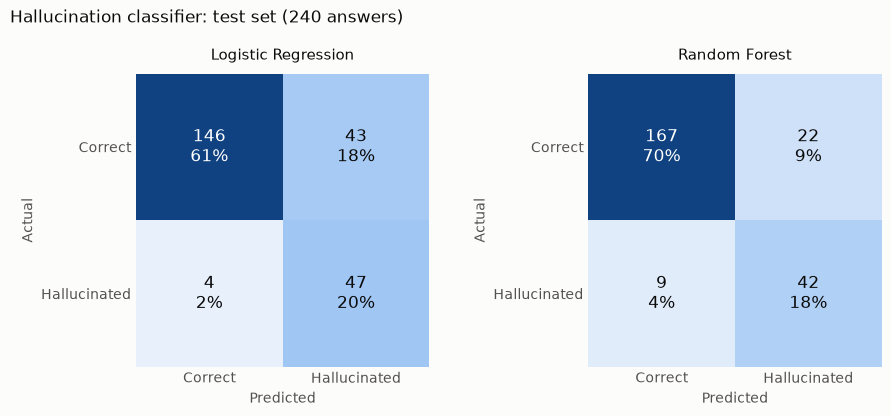

In [6]:
def plot_confusions(names, path):
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names), 4.2))
    for ax, name in zip(np.atleast_1d(axes), names):
        cm = confusion_matrix(y_test, PRED[name])
        share = cm / cm.sum()
        ax.imshow(share, cmap=BLUES, vmin=0, vmax=share.max())
        for (i, j), n in np.ndenumerate(cm):
            dark = share[i, j] > 0.55 * share.max()
            ax.text(j, i, f"{n}\n{100 * share[i, j]:.0f}%", ha="center", va="center",
                    fontsize=12, color="white" if dark else INK)
        ax.set_xticks([0, 1], ["Correct", "Hallucinated"])
        ax.set_yticks([0, 1], ["Correct", "Hallucinated"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(name, fontsize=11, color=INK, pad=10)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.tick_params(length=0)
    fig.suptitle(f"Hallucination classifier: test set ({len(y_test)} answers)", fontsize=12, x=0.02, ha="left")
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

plot_confusions(["Logistic Regression", "Random Forest"], config.FIG_DIR / "confusion_matrix.png")

## 4.7 SHAP: what drives the predictions?

**SHAP** splits each prediction into contributions from each feature: how much did *this* feature push *this* answer towards "hallucinated" (right, positive) or "correct" (left, negative)?

In the **summary plot**, each dot is one test answer. Its position shows the feature's push, and its colour shows the feature's value (red = high, blue = low). Features are sorted by overall importance.

- **Random Forest**: `TreeExplainer` (exact for tree models), in probability units.
- **Logistic Regression**: `LinearExplainer`, in log-odds units. Numbers were standardised, so "high/low" means above/below average.

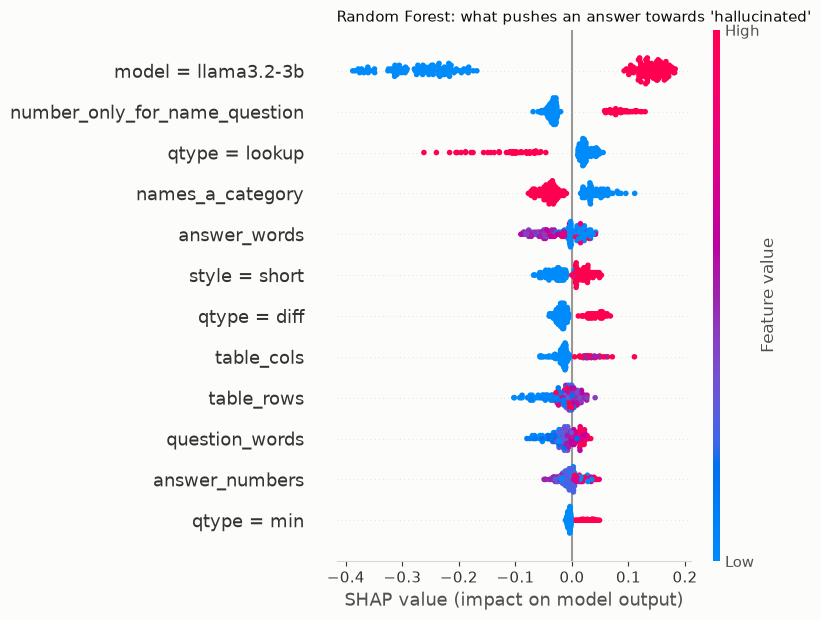

In [7]:
def shap_inputs(model, X_part):
    "The model's own input matrix (after one-hot encoding), with readable column names."
    prep = model.named_steps["prep"]
    names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    for c in CATEGORICAL:                                    # 'model_llama3.2-3b' -> 'model = llama3.2-3b'
        names = [n.replace(f"{c}_", f"{c} = ", 1) if n.startswith(f"{c}_") else n for n in names]
    return pd.DataFrame(prep.transform(X_part), columns=names, index=X_part.index)

rf = models["Random Forest"]
Xt_rf = shap_inputs(rf, X_test)
rf_explainer = shap.TreeExplainer(rf.named_steps["clf"])
rf_shap = rf_explainer(Xt_rf)
if rf_shap.values.ndim == 3:                                 # (answers, features, classes) -> class 1
    rf_shap = rf_shap[:, :, 1]

plt.figure()
shap.summary_plot(rf_shap.values, Xt_rf, max_display=12, show=False)
plt.title("Random Forest: what pushes an answer towards 'hallucinated'", fontsize=11, loc="left")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "shap_summary_rf.png", dpi=200, bbox_inches="tight")
plt.show()

Background dataset has 560 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=560 when initializing the masker.


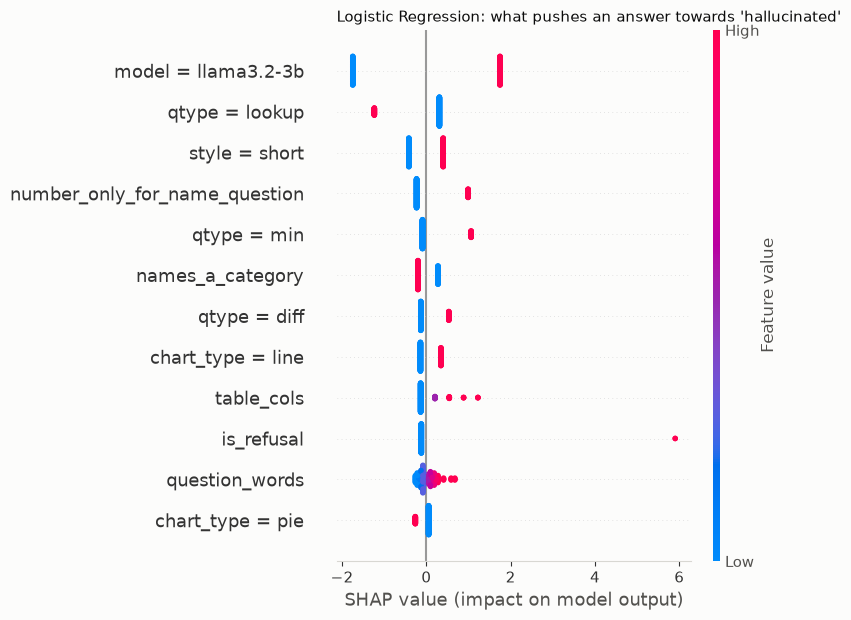

In [8]:
lr = models["Logistic Regression"]
Xtr_lr, Xt_lr = shap_inputs(lr, X_train), shap_inputs(lr, X_test)
lr_explainer = shap.LinearExplainer(lr.named_steps["clf"], Xtr_lr)
lr_shap = lr_explainer(Xt_lr)

plt.figure()
shap.summary_plot(lr_shap.values, Xt_lr, max_display=12, show=False)
plt.title("Logistic Regression: what pushes an answer towards 'hallucinated'", fontsize=11, loc="left")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "shap_summary_lr.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Overall importance side by side: mean |SHAP| per feature, top 10 for each model
importance = pd.DataFrame({
    "Random Forest": np.abs(rf_shap.values).mean(0),
    "Logistic Regression": pd.Series(np.abs(lr_shap.values).mean(0), index=Xt_lr.columns)
                             .reindex(Xt_rf.columns).values,
}, index=Xt_rf.columns)
importance["RF rank"] = importance["Random Forest"].rank(ascending=False).astype(int)
importance["LR rank"] = importance["Logistic Regression"].rank(ascending=False).astype(int)
importance.sort_values("RF rank").head(10).round(4)

,Random Forest,Logistic Regression,RF rank,LR rank
model = llama3.2-3b,0.2050,1.7460,1,1
number_only_for_name_question,0.0462,0.4027,2,4
qtype = lookup,0.0437,0.4939,3,2
names_a_category,0.0414,0.2290,4,6
answer_words,0.0268,0.0416,5,18
style = short,0.0253,0.4067,6,3
qtype = diff,0.0248,0.2261,7,7
table_cols,0.0200,0.1913,8,9
table_rows,0.0196,0.0044,9,22
question_words,0.0189,0.1532,10,11


## 4.8 Individual explanations

Three test answers explained one at a time with the Random Forest (each bar shows how one feature moved this answer's risk up or down from the average):

1. **Caught**: a hallucination the classifier flagged with high confidence,
2. **Trusted**: a correct answer it rated as safe,
3. **Missed**: a hallucination it rated as safe. These show the classifier's blind spots, so they're worth discussing honestly.


=== CAUGHT  (predicted risk 0.95) ===
llama3.2-3b | short | diff
Q: What is the difference of franchise in the year 2020 and 2011
True answer: 505
LLM said:    145


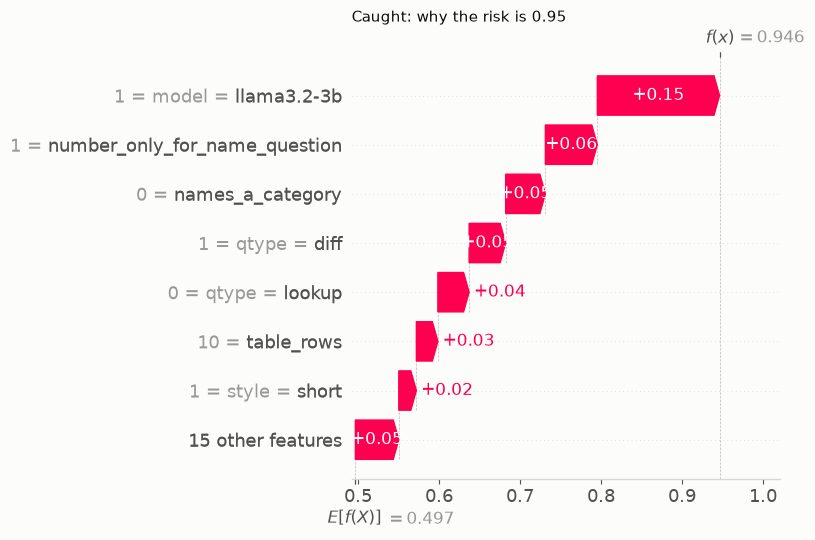


=== TRUSTED  (predicted risk 0.01) ===
gemini-flash | sentence | lookup
Q: What was the population of Bahrain in 2019?
True answer: 1.48
LLM said:    The population of Bahrain in 2019 was 1.48 million inhabitants.


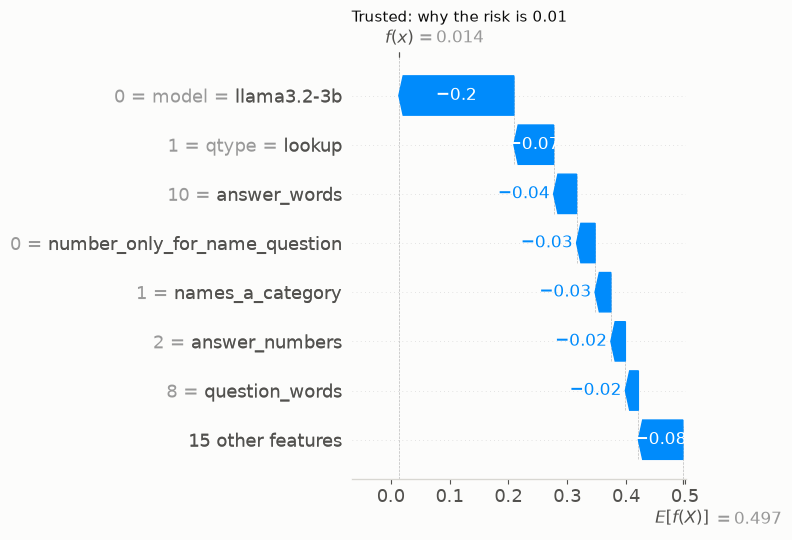


=== MISSED  (predicted risk 0.26) ===
llama3.2-3b | sentence | lookup
Q: What was the total net revenues of Medco Health Solutions in 2008?
True answer: 51258
LLM said:    The total net revenues of Medco Health Solutions in 2008 were 51.258 million U.S. dollars.


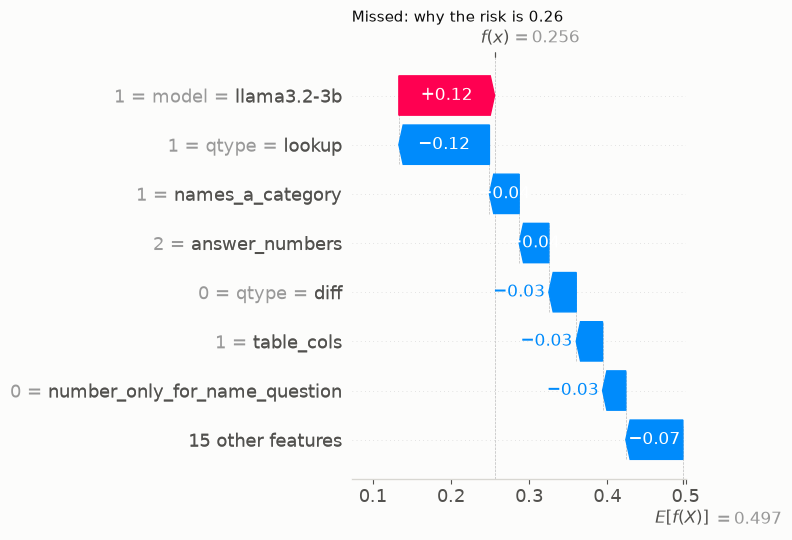

In [10]:
test = v.iloc[test_idx].assign(risk=PROB["Random Forest"], pred=PRED["Random Forest"], actual=y_test)
picks = {
    "caught":  test[(test.actual == 1) & (test.pred == 1)].sort_values("risk", ascending=False),
    "trusted": test[(test.actual == 0) & (test.pred == 0)].sort_values("risk"),
    "missed":  test[(test.actual == 1) & (test.pred == 0)].sort_values("risk"),
}
for kind, frame in picks.items():
    if frame.empty:
        print(f"No '{kind}' example in the test set.")
        continue
    r = frame.iloc[0]
    pos = test.index.get_loc(r.name)
    print(f"\n=== {kind.upper()}  (predicted risk {r.risk:.2f}) ===")
    print(f"{r.model} | {r['style']} | {r.qtype}")
    print(f"Q: {r.query}\nTrue answer: {r.label}\nLLM said:    {r.llm_answer}")
    plt.figure()
    shap.plots.waterfall(rf_shap[pos], max_display=8, show=False)
    plt.title(f"{kind.capitalize()}: why the risk is {r.risk:.2f}", fontsize=11, loc="left")
    plt.tight_layout()
    plt.savefig(config.FIG_DIR / f"shap_example_{kind}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 4.9 Sanity check: the circular classifier (not used)

For completeness, here is the classifier **as originally specified**, with `num_deviation`, `fuzzy_score` and `cosine_sim` added as features. These are computed **against the true answer**, so this model would be useless in practice (if you had the true answer, you wouldn't need a classifier). Expect near-perfect scores: that is the circularity, not a better model.

In [11]:
oracle_feats = v[["num_deviation", "fuzzy_score", "cosine_sim"]].copy()
oracle_feats = oracle_feats.loc[:, oracle_feats.notna().any()]          # drop a column that is empty
for c in list(oracle_feats.columns):
    oracle_feats[c + "_missing"] = oracle_feats[c].isna().astype(int)   # NaN = not applicable
    oracle_feats[c] = oracle_feats[c].fillna(-1)
X_circ = pd.concat([X, oracle_feats], axis=1)

circ = Pipeline([
    ("prep", ColumnTransformer([("cat", one_hot(), CATEGORICAL),
                                ("num", "passthrough", NUMERIC + list(oracle_feats.columns))])),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                   random_state=config.SEED, n_jobs=-1))])
circ.fit(X_circ.iloc[train_idx], y_train)
p = circ.predict(X_circ.iloc[test_idx])
circular = pd.Series({"precision": precision_score(y_test, p), "recall": recall_score(y_test, p),
                      "F1": f1_score(y_test, p),
                      "ROC_AUC": roc_auc_score(y_test, circ.predict_proba(X_circ.iloc[test_idx])[:, 1])}).round(3)
circular.to_csv(config.TABLE_OUT / "classifier_circular_sanity.csv")
print("Circular classifier (uses the true answer):")
circular

Circular classifier (uses the true answer):


precision    0.98
recall       0.98
F1           0.98
ROC_AUC      1.00
dtype: float64

## 4.10 Save predictions for Section 6

In [12]:
out = v.iloc[test_idx][["qid", "model", "style", "qtype", "chart_type", "hallucinated"]].copy()
for name in models:
    out[f"risk_{name.split(' (')[0].replace(' ', '_').lower()}"] = PROB[name]
out.to_csv(config.OUTPUT_DIR / "classifier_predictions.csv", index=False)
print(f"Saved {len(out)} test predictions -> outputs/classifier_predictions.csv")
print("Figures saved in outputs/figures/: confusion_matrix.png, shap_summary_rf.png, "
      "shap_summary_lr.png, shap_example_*.png")

Saved 240 test predictions -> outputs/classifier_predictions.csv
Figures saved in outputs/figures/: confusion_matrix.png, shap_summary_rf.png, shap_summary_lr.png, shap_example_*.png


## ✅ Checkpoint and how to report it

1. **4.3** printed `shared questions: 0` (no leakage).
2. **4.4 / 4.5:** do both full models beat the baseline? If yes, the classifier learns more than "which model answered". Report the **cross-validated** numbers (mean ± sd) as the main result; the single split is one example.
3. **4.7:** which features matter most, and do both models broadly agree? Agreement between two different model types makes the explanation more trustworthy.
4. **4.8:** use the three examples in the report, especially the **missed** one, honestly.
5. **4.9:** near-perfect, as expected. One sentence in the report: *"Using the verifier's own similarity scores as features would be circular; we exclude them."*

**Limits:** 800 answers from only 200 questions and 2 models; the label comes from the automatic verifier (audited at precision 0.98, recall 1.00, on 120 answers). A classifier trained on Llama and Gemini may not transfer to other LLMs.